<div align="center">

<h1> <b> RADIO NUCLEAR A PARTIR DE LAS ENERGÍAS DE DESPLAZAMIENTO DE COULOMB EN NÚCLEOS ESPEJO </b> </h1>

</div>

<br>

<hr size=10 noshade color="green">
<p>
<p><img alt="UdeA logo" height="180px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="100px" vspace="4px"></p>

<div align="right">       

<h3><i> <b>Giovanni Stiven Rojas Benjumea <br>
Cristian Camilo Vergara Restrepo</b> <br>  
Universidad de Antioquia <br>
Instituto de Física  <br>
</i></h3>
</div>

---

## 1. Introducción

Los núcleos espejo son pares de núcleos con el mismo número másico $A$ en los que el número de protones de uno coincide con el número de neutrones del otro: $(Z,N)$ y $(N,Z)$. Bajo la hipótesis de simetría de carga de la fuerza nuclear, la interacción nuclear fuerte es idéntica para ambos miembros del par, de modo que la diferencia de energía de enlace entre ellos se debe, en muy buena aproximación, únicamente a la diferencia de energía electrostática asociada al protón adicional.

Este notebook analiza el archivo `delta_coulomb.dat`, que contiene, para una serie de pares de núcleos espejo con $A$ impar entre 3 y 59, dos columnas:

- **Columna 1:** el número másico $A$.
- **Columna 2:** la energía de desplazamiento coulombiano $\Delta E_C$, en keV.

**Modelo.** Si el núcleo se representa como una esfera uniformemente cargada de radio $R = r_0 A^{1/3}$, su energía coulombiana es

$$
E_C(Z) = \frac{3}{5}\,\frac{e^2}{4\pi\epsilon_0\,R}\,Z(Z-1).
$$

Para $A$ impar, un par espejo tiene exactamente $Z_> = (A+1)/2$ protones en el miembro más rico en protones y $Z_< = (A-1)/2$ en el otro, de modo que $Z_> - Z_< = 1$ y $Z_> + Z_< = A$. La energía de desplazamiento coulombiano es entonces

$$
\Delta E_C = E_C(Z_>) - E_C(Z_<)
= \frac{3}{5}\,\frac{e^2}{4\pi\epsilon_0\,R}\big[Z_>(Z_>-1) - Z_<(Z_<-1)\big]
= \frac{3}{5}\,\frac{e^2}{4\pi\epsilon_0\,r_0}\left(A^{2/3} - A^{-1/3}\right),
$$

donde se usó $R = r_0 A^{1/3}$. El término $A^{-1/3}$ no es despreciable en los núcleos más ligeros (para $A = 3$ vale un tercio de $A^{2/3}$), pero varía lentamente con $A$. Junto con correcciones que el modelo de esfera uniforme no incluye (la difusividad de la superficie nuclear, la energía de intercambio coulombiano y los efectos de capa), suele absorberse en una constante, de modo que los datos se describen mediante la relación lineal

$$
\Delta E_C \,(\text{MeV}) = m\,A^{2/3} + b, \qquad
m = \frac{3}{5}\,\frac{e^2}{4\pi\epsilon_0\,r_0}.
$$

De la pendiente $m$ se obtiene el radio nuclear:

$$
r_0 = \frac{3}{5}\,\frac{e^2}{4\pi\epsilon_0\,m}.
$$

$m$ y $r_0$ son positivos, pues $\Delta E_C$ crece con $A$: agregar un protón adicional siempre incrementa la energía coulombiana del núcleo. Para la constante $e^2/(4\pi\epsilon_0)$ se usa el valor estándar en unidades nucleares, $e^2/(4\pi\epsilon_0) \approx 1.44$ MeV·fm (Krane, 1988).

El procedimiento consiste en:

1. Convertir $\Delta E_C$ de keV a MeV y calcular $A^{2/3}$.
2. Ajustar por mínimos cuadrados la relación lineal $\Delta E_C = m\,A^{2/3} + b$.
3. Obtener $r_0$, con su incertidumbre, a partir de la pendiente $m$.
4. Graficar $\Delta E_C$ frente a $A^{2/3}$ junto con el ajuste, y los residuos del ajuste frente a $A^{2/3}$, para evaluar la calidad del modelo lineal.
5. Comparar el valor de $r_0$ con el que se obtiene al ajustar la expresión completa de la esfera uniforme, para estimar cuánto depende el resultado de la forma del modelo.

## 2. Carga y preparación de los datos

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Archivo de datos: numero masico A y energia de desplazamiento
# coulombiano Delta_E_C (en keV) para cada par de nucleos espejo.
RUTA_DATOS = "delta_coulomb.dat"

datos = np.loadtxt(RUTA_DATOS)
A = datos[:, 0]
delta_Ec_keV = datos[:, 1]

# El modelo de la Seccion 1 esta expresado en MeV; se convierte una
# sola vez para no repetir la conversion en cada calculo posterior.
delta_Ec = delta_Ec_keV / 1000.0

# Variable independiente del ajuste lineal (ver Seccion 1).
x = A**(2 / 3)

print(f"Numero de pares de nucleos espejo: {len(A)}")
print(f"Rango de A: {A.min():.0f} - {A.max():.0f}")
print(f"Rango de Delta_E_C: {delta_Ec.min():.3f} - {delta_Ec.max():.3f} MeV")

Numero de pares de nucleos espejo: 27
Rango de A: 3 - 59
Rango de Delta_E_C: 0.764 - 9.874 MeV


## 3. Ajuste lineal por mínimos cuadrados

Se ajusta el modelo $\Delta E_C = m\,A^{2/3} + b$ a los datos experimentales mediante mínimos cuadrados no lineales (`scipy.optimize.curve_fit`), y se obtiene el radio nuclear $r_0$, con su incertidumbre asociada, a partir de la pendiente del ajuste.

In [2]:
def modelo_lineal(x, m, b):
    """
    Modelo lineal Delta_E_C = m*x + b, con x = A^(2/3) (ver Seccion 1).

    Parameters
    ----------
    x : array_like
        Valores de A^(2/3) (adimensional).
    m : float
        Pendiente del ajuste, en MeV.
    b : float
        Intercepto del ajuste, en MeV.

    Returns
    -------
    array_like
        Delta_E_C predicho por el modelo, en MeV.
    """
    return m * x + b


# Ajuste por minimos cuadrados de m y b. No se cuenta con incertidumbres
# experimentales por punto, de modo que curve_fit asume errores iguales
# y escala la covarianza con la varianza residual (absolute_sigma=False,
# el comportamiento por defecto).
popt, pcov = curve_fit(modelo_lineal, x, delta_Ec)
m, b = popt
error_m, error_b = np.sqrt(np.diag(pcov))

# Constante e^2/(4*pi*eps0) en unidades nucleares (MeV*fm; Krane, 1988).
e2_4pieps0 = 1.44  # MeV*fm

# Radio nuclear a partir de la pendiente del ajuste (ver Seccion 1),
# con su incertidumbre propagada linealmente desde la de m.
r0_fm = (3 * e2_4pieps0) / (5 * m)
error_r0_fm = r0_fm * (error_m / m)

# Bondad del ajuste (coeficiente de determinacion R^2).
prediccion = modelo_lineal(x, *popt)
ss_res = np.sum((delta_Ec - prediccion)**2)
ss_tot = np.sum((delta_Ec - delta_Ec.mean())**2)
r_cuadrado = 1 - ss_res / ss_tot

print(f"m = {m:.4f} +/- {error_m:.4f} MeV")
print(f"b = {b:.4f} +/- {error_b:.4f} MeV")
print(f"R^2 = {r_cuadrado:.4f}")
print(f"r0 = {r0_fm:.3f} +/- {error_r0_fm:.3f} fm")

m = 0.7076 +/- 0.0070 MeV
b = -0.9291 +/- 0.0687 MeV
R^2 = 0.9976
r0 = 1.221 +/- 0.012 fm


## 4. Gráfica de $\Delta E_C$ frente a $A^{2/3}$

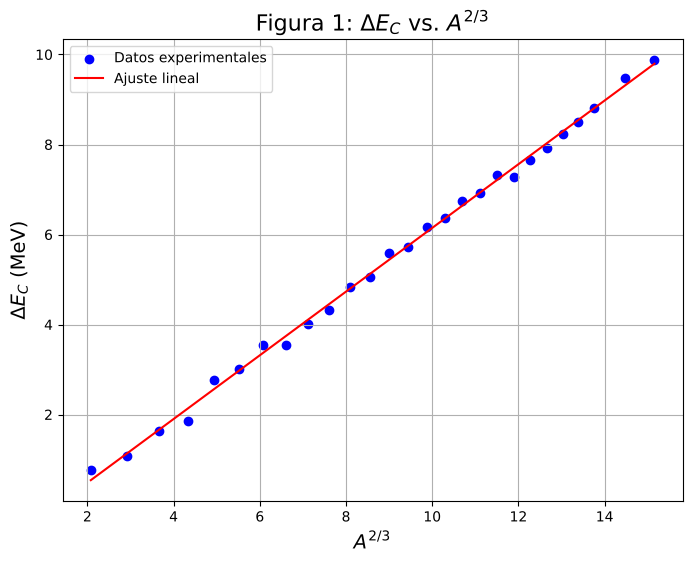

In [3]:
plt.figure(figsize=(8, 6))
plt.scatter(x, delta_Ec, color="blue", label="Datos experimentales")
plt.plot(x, modelo_lineal(x, *popt), color="red", label="Ajuste lineal")
plt.xlabel(r"$A^{2/3}$", fontsize=14)
plt.ylabel(r"$\Delta E_C$ (MeV)", fontsize=14)
plt.title(r"Figura 1: $\Delta E_C$ vs. $A^{2/3}$", fontsize=16)
plt.legend()
plt.grid(True)
plt.show()

**Figura 1**: los puntos azules son los valores experimentales de $\Delta E_C$ para cada par de núcleos espejo, y la línea roja es el ajuste lineal obtenido por mínimos cuadrados. La tendencia lineal entre $\Delta E_C$ y $A^{2/3}$, con un coeficiente de determinación cercano a 1, respalda el modelo de esfera uniformemente cargada para la energía coulombiana nuclear.

## 5. Análisis de residuos

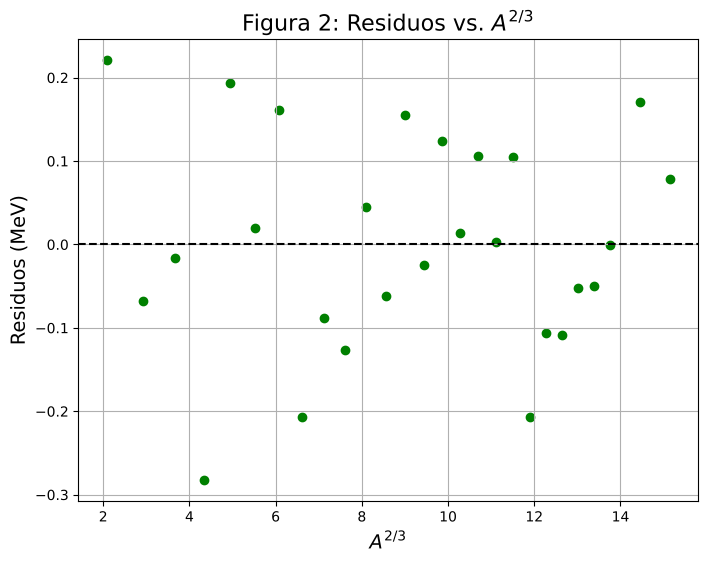

In [4]:
# Residuos del ajuste lineal.
residuos = delta_Ec - modelo_lineal(x, *popt)

plt.figure(figsize=(8, 6))
plt.scatter(x, residuos, color="green")
plt.axhline(0, color="black", linestyle="--")
plt.xlabel(r"$A^{2/3}$", fontsize=14)
plt.ylabel("Residuos (MeV)", fontsize=14)
plt.title(r"Figura 2: Residuos vs. $A^{2/3}$", fontsize=16)
plt.grid(True)
plt.show()

**Figura 2**: residuos $\Delta E_C - (\text{ajuste})$ frente a $A^{2/3}$. Su dispersión (unos 0.13 MeV) es pequeña frente al rango de $\Delta E_C$ (de 0.8 a 9.9 MeV), y no muestran una curvatura global, de modo que la relación lineal describe bien la tendencia de los datos. Los residuos tienen, sin embargo, una estructura que el modelo de esfera uniforme no contiene, que se examina a continuación.

### 5.1. Estructura de los residuos

Dos rasgos de los residuos se repiten a lo largo de la serie. El primero es una alternancia según la paridad del número de protones: el residuo de cada par espejo tiende a tener signo opuesto al de sus vecinos. El segundo son los cambios bruscos en los cierres de capa: $\Delta E_C$ apenas cambia de $A = 15$ a $A = 17$ y disminuye de $A = 39$ a $A = 41$, a pesar de que el modelo predice un aumento. La celda siguiente cuantifica ambos.

In [5]:
Z_menor = (A - 1) / 2          # protones del miembro del par con menos protones
impar = Z_menor % 2 == 1
for etiqueta, mascara in [("Z< impar (Z> par)", impar), ("Z< par (Z> impar)", ~impar)]:
    r = residuos[mascara]
    print(f"{etiqueta}: {mascara.sum():2d} pares, residuo medio = {r.mean():+.3f} "
          f"+/- {r.std(ddof=1) / np.sqrt(r.size):.3f} MeV")

print("\nCierres de capa (Delta_E_C en MeV):")
for a1, a2 in [(15, 17), (39, 41)]:
    e1 = delta_Ec[A == a1][0]
    e2 = delta_Ec[A == a2][0]
    print(f"  A = {a1} -> {a2}: {e1:.3f} -> {e2:.3f} (diferencia {e2 - e1:+.3f}; "
          f"el ajuste lineal predice {modelo_lineal(a2**(2/3), *popt) - modelo_lineal(a1**(2/3), *popt):+.3f})")

Z< impar (Z> par): 15 pares, residuo medio = +0.073 +/- 0.027 MeV
Z< par (Z> impar): 12 pares, residuo medio = -0.092 +/- 0.028 MeV

Cierres de capa (Delta_E_C en MeV):
  A = 15 -> 17: 3.536 -> 3.543 (diferencia +0.007; el ajuste lineal predice +0.375)
  A = 39 -> 41: 7.313 -> 7.278 (diferencia -0.035; el ajuste lineal predice +0.276)


Cuando el miembro rico en protones del par tiene un número par de protones, el protón añadido completa un par y la energía de desplazamiento es en promedio mayor que la del ajuste; cuando lo tiene impar, el protón queda desapareado y la energía es menor. Esta alternancia es una manifestación conocida del apareamiento de protones en las energías coulombianas (Carlson y Talmi, 1954; Nolen y Schiffer, 1969). Los cambios en $A = 15 \to 17$ y $A = 39 \to 41$ coinciden con los cierres de capa de $^{16}\mathrm{O}$ y $^{40}\mathrm{Ca}$: el nucleón adicional ocupa una capa nueva ($1d_{5/2}$ y $1f_{7/2}$, respectivamente), cuya órbita es más extensa que el núcleo cerrado, de modo que su repulsión coulombiana con los demás protones es menor que la que supone una esfera uniforme.

### 5.2. Dependencia de $r_0$ con la forma del modelo

La relación lineal $\Delta E_C = m A^{2/3} + b$ es una de varias formas razonables del modelo. Se comparan tres: la lineal con término constante, la expresión exacta de la esfera uniforme sin parámetros adicionales ($\Delta E_C = m\,(A^{2/3} - A^{-1/3})$) y esa misma expresión con un término constante que represente las correcciones no incluidas.

In [6]:
x_esfera = A**(2 / 3) - A**(-1 / 3)
modelos = {
    "m A^(2/3) + b": (lambda x, m, b: m * x + b, x),
    "m (A^(2/3) - A^(-1/3))": (lambda x, m: m * x, x_esfera),
    "m (A^(2/3) - A^(-1/3)) + b": (lambda x, m, b: m * x + b, x_esfera),
}
print(f"{'Modelo':<28}{'r0 (fm)':>16}{'b (MeV)':>12}{'rms (MeV)':>12}")
for nombre, (funcion, variable) in modelos.items():
    p, c = curve_fit(funcion, variable, delta_Ec)
    e = np.sqrt(np.diag(c))
    r0_modelo = 3 * e2_4pieps0 / (5 * p[0])
    sig_r0 = r0_modelo * e[0] / p[0]
    rms = np.sqrt(np.mean((delta_Ec - funcion(variable, *p))**2))
    b_txt = f"{p[1]:+.3f}" if len(p) > 1 else "-"
    print(f"{nombre:<28}{r0_modelo:>9.3f} +/- {sig_r0:.3f}{b_txt:>12}{rms:>12.3f}")

Modelo                               r0 (fm)     b (MeV)   rms (MeV)
m A^(2/3) + b                   1.221 +/- 0.012      -0.929       0.128
m (A^(2/3) - A^(-1/3))          1.351 +/- 0.011           -       0.244
m (A^(2/3) - A^(-1/3)) + b      1.254 +/- 0.013      -0.512       0.137


---

## 6. Conclusiones

1. **Validez del modelo lineal.** La relación $\Delta E_C = m\,A^{2/3} + b$ describe la tendencia de las energías de desplazamiento coulombiano de los 27 pares espejo con un residuo de unos 0.13 MeV ($R^2 \approx 0.998$). Los residuos no son aleatorios: alternan con la paridad del número de protones y cambian bruscamente en los cierres de capa de $^{16}\mathrm{O}$ y $^{40}\mathrm{Ca}$, efectos de apareamiento y de estructura de capas que una esfera uniformemente cargada no contiene.

2. **Radio nuclear.** La pendiente del ajuste lineal da $r_0 = 1.221 \pm 0.012$ fm, donde la incertidumbre es solo estadística. La forma del modelo introduce una incertidumbre mayor: la expresión exacta de la esfera uniforme con término constante da $r_0 = 1.254 \pm 0.013$ fm, y sin él, $r_0 = 1.35$ fm con un ajuste claramente peor. Los modelos que describen bien los datos dan $r_0$ entre 1.22 y 1.25 fm, en el rango de los radios de la distribución de carga obtenidos por dispersión de electrones ($r_0 \approx 1.2$ fm; Krane, 1988).

3. **Consistencia física.** Que una única constante $r_0$ describa la tendencia de todos los pares espejo, con un valor próximo al de la distribución de carga, respalda la hipótesis de simetría de carga de la fuerza nuclear: la diferencia de energía entre los miembros de cada par es esencialmente electrostática. El término constante negativo del ajuste y la estructura de los residuos indican, a su vez, los límites del modelo de esfera uniforme.

---

## Referencias

Carlson, B. C., & Talmi, I. (1954). Pairing effects in Coulomb energies and the radii of mirror nuclei. *Physical Review*, *96*(2), 436–444. https://doi.org/10.1103/PhysRev.96.436

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, *585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, *9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Krane, K. S. (1988). *Introductory nuclear physics*. John Wiley & Sons.

Nolen, J. A., & Schiffer, J. P. (1969). Coulomb energies. *Annual Review of Nuclear Science*, *19*, 471–526. https://doi.org/10.1146/annurev.ns.19.120169.002351

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … van Mulbregt, P. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, *17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2

*Nota:* los valores de $\Delta E_C$ empleados corresponden a 27 pares de núcleos espejo con $A$ impar entre 3 y 59, en el formato de las tablas de energías de desplazamiento coulombiano de la física nuclear (Krane, 1988); el archivo `delta_coulomb.dat` no indica la compilación de la que se tomaron los valores.